In [31]:
%pip install numpy pandas scikit-learn librosa matplotlib tensorflow soundfile scipy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [52]:

from pathlib import Path
from scipy.signal import resample
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import scipy.sparse as sp

from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report
from sklearn.preprocessing import (
    MultiLabelBinarizer,
    StandardScaler,
    normalize,
    LabelEncoder
)

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers, models

print("Libraries imported successfully!")

Libraries imported successfully!


In [33]:
# Music4All lives in datasets/music4all (see README). Works from the repo root or a subfolder.
repo_root = Path.cwd()
if not (repo_root / "datasets").exists() and (repo_root.parent / "datasets").exists():
    repo_root = repo_root.parent
data_path = repo_root / "datasets" / "music4all"

print("Dataset exists:", data_path.exists())

for file in data_path.iterdir():
    print(file.name)

Dataset exists: True
audios
id_genres.csv
id_information.csv
id_lang.csv
id_metadata.csv
id_tags.csv
listening_history.csv
lyrics
readme.txt


In [34]:
songs = pd.read_csv(
    data_path / "id_information.csv",
    sep="\t",
    dtype={"id": str}
)

genres = pd.read_csv(
    data_path / "id_genres.csv",
    sep="\t",
    dtype={"id": str}
)

print("Songs:", songs.shape)
print("Genres:", genres.shape)

display(songs.head())
display(genres.head())

Songs: (109269, 4)
Genres: (109269, 2)


,id,artist,song,album_name
0,0009fFIM1eYThaPg,Cheryl,Rain on Me,3 Words
1,0010xmHR6UICBOYT,Oddisee,After Thoughts,The Beauty in All
2,002Jyd0vN4HyCpqL,Blue Öyster Cult,ME 262,Secret Treaties
3,006TYKNjNxWjfKjy,Rhapsody,Flames of Revenge,Legendary Years (Re-Recorded)
4,007LIJOPQ4Sb98qV,The Chameleons,Nostalgia,What Does Anything Mean? Basically (2009 Remas...


,id,genres
0,0009fFIM1eYThaPg,pop
1,0010xmHR6UICBOYT,underground hip hop
2,002Jyd0vN4HyCpqL,"hard rock,rock,classic rock"
3,006TYKNjNxWjfKjy,"symphonic metal,power metal,symphonic power metal"
4,007LIJOPQ4Sb98qV,"post-punk,new wave"


In [35]:
df = pd.merge(
    songs,
    genres,
    on="id",
    how="left"
)

df = df.drop_duplicates(subset="id")
df = df.reset_index(drop=True)

df["genres"] = df["genres"].fillna("")

print("Combined shape:", df.shape)
display(df.head())

Combined shape: (109269, 5)


,id,artist,song,album_name,genres
0,0009fFIM1eYThaPg,Cheryl,Rain on Me,3 Words,pop
1,0010xmHR6UICBOYT,Oddisee,After Thoughts,The Beauty in All,underground hip hop
2,002Jyd0vN4HyCpqL,Blue Öyster Cult,ME 262,Secret Treaties,"hard rock,rock,classic rock"
3,006TYKNjNxWjfKjy,Rhapsody,Flames of Revenge,Legendary Years (Re-Recorded),"symphonic metal,power metal,symphonic power metal"
4,007LIJOPQ4Sb98qV,The Chameleons,Nostalgia,What Does Anything Mean? Basically (2009 Remas...,"post-punk,new wave"


In [36]:
audio_path = data_path / "audios"

audio_files = [
    p for p in audio_path.rglob("*")
    if p.suffix.lower() in {
        ".mp3", ".wav", ".flac", ".ogg"
    }
]

print("Audio files found:", len(audio_files))

for file in audio_files[:5]:
    print(file)

Audio files found: 0


In [37]:
# Find all MP3 files inside the Music4All dataset
audio_files = list(data_path.rglob("*.mp3"))

print("Audio files found:", len(audio_files))

# Display the first 10 files
for file in audio_files[:10]:
    print(file.name)

Audio files found: 109269
0009fFIM1eYThaPg.mp3
0010xmHR6UICBOYT.mp3
002Jyd0vN4HyCpqL.mp3
006TYKNjNxWjfKjy.mp3
007LIJOPQ4Sb98qV.mp3
00b6fV3nx5z2b8Ls.mp3
00CH4HJdxQQQbJfu.mp3
00DZ3XCAQb2FdCc6.mp3
00GCd9HYEge6Ntwi.mp3
00hFmpewuNvc4dRL.mp3


In [38]:
# Create a dictionary connecting IDs to audio file locations
audio_by_id = {}

for file in audio_files:
    song_id = file.stem
    audio_by_id[song_id] = file

# Check which songs have matching recordings
df["audio_path"] = df["id"].map(audio_by_id)

# Keep songs that actually have audio
df = df.dropna(subset=["audio_path"]).reset_index(drop=True)

print("Songs with matching audio:", len(df))

display(df[["id", "artist", "song", "audio_path"]].head())

Songs with matching audio: 109269


,id,artist,song,audio_path
0,0009fFIM1eYThaPg,Cheryl,Rain on Me,C:\Users\garri\AI_Project\music4all\music4all\...
1,0010xmHR6UICBOYT,Oddisee,After Thoughts,C:\Users\garri\AI_Project\music4all\music4all\...
2,002Jyd0vN4HyCpqL,Blue Öyster Cult,ME 262,C:\Users\garri\AI_Project\music4all\music4all\...
3,006TYKNjNxWjfKjy,Rhapsody,Flames of Revenge,C:\Users\garri\AI_Project\music4all\music4all\...
4,007LIJOPQ4Sb98qV,The Chameleons,Nostalgia,C:\Users\garri\AI_Project\music4all\music4all\...


In [39]:
# Extract the first genre from each song
df["primary_genre"] = df["genres"].apply(
    lambda x: x.split(",")[0].strip().lower()
    if x.strip() else ""
)

# Remove songs without a genre
df = df[df["primary_genre"] != ""].copy()

# Count the number of songs in each genre
genre_counts = df["primary_genre"].value_counts()

print(genre_counts.head(15))

primary_genre
pop                  13621
rock                  9286
electronic            5596
indie rock            4003
folk                  3669
soul                  3271
rap                   3195
alternative rock      2409
classic rock          2237
singer-songwriter     2003
indie pop             1912
mpb                   1720
post-hardcore         1580
ambient               1532
soundtrack            1531
Name: count, dtype: int64


In [40]:
# Select the most common genres
top_genres = genre_counts.head(8).index.tolist()

# Keep only songs belonging to those genres
df = df[df["primary_genre"].isin(top_genres)].copy()

print("Selected genres:", top_genres)
print("Songs available:", len(df))

Selected genres: ['pop', 'rock', 'electronic', 'indie rock', 'folk', 'soul', 'rap', 'alternative rock']
Songs available: 45050


In [41]:
# Select up to 200 songs from each genre
sampled_songs = []

for genre in top_genres:

    genre_songs = df[df["primary_genre"] == genre]

    # Skip genres with too few examples
    if len(genre_songs) < 30:
        continue

    selected = genre_songs.sample(
        n=min(200, len(genre_songs)),
        random_state=42
    )

    sampled_songs.append(selected)

# Combine the selected songs
df = pd.concat(
    sampled_songs,
    ignore_index=True
)

print("Final sample size:", len(df))
print(df["primary_genre"].value_counts())

Final sample size: 1600
primary_genre
pop                 200
rock                200
electronic          200
indie rock          200
folk                200
soul                200
rap                 200
alternative rock    200
Name: count, dtype: int64


In [42]:
def extract_audio_features(audio_path):

    try:

        # Load the MP3 recording
        y, sr = librosa.load(
            str(audio_path),
            sr=22050,
            mono=True,
            duration=15
        )

        # Skip empty recordings
        if len(y) == 0:
            return None

        # Create Mel spectrogram
        mel = librosa.feature.melspectrogram(
            y=y,
            sr=sr,
            n_mels=128,
            n_fft=2048,
            hop_length=512
        )

        # Convert to decibels
        mel_db = librosa.power_to_db(
            mel,
            ref=np.max
        )

        # Resize the time dimension to 128 frames
        mel_db = resample(
            mel_db,
            128,
            axis=1
        )

        # Normalize spectrogram
        mel_db = (
            mel_db - mel_db.mean()
        ) / (mel_db.std() + 1e-8)

        # Extract additional audio characteristics
        mfcc = librosa.feature.mfcc(
            y=y,
            sr=sr,
            n_mfcc=13
        )

        spectral_centroid = librosa.feature.spectral_centroid(
            y=y,
            sr=sr
        ).mean()

        spectral_bandwidth = librosa.feature.spectral_bandwidth(
            y=y,
            sr=sr
        ).mean()

        zero_crossing = librosa.feature.zero_crossing_rate(
            y
        ).mean()

        tempo = librosa.feature.tempo(
            y=y,
            sr=sr
        )[0]

        # Combine the numerical audio features
        audio_features = np.concatenate([
            mfcc.mean(axis=1),
            [spectral_centroid],
            [spectral_bandwidth],
            [zero_crossing],
            [tempo]
        ])

        return mel_db, audio_features

    except Exception as e:

        print("Could not process:", audio_path)
        print(e)

        return None

In [43]:
mel_spectrograms = []
audio_feature_list = []
valid_rows = []

for index, row in df.iterrows():

    result = extract_audio_features(
        row["audio_path"]
    )

    # Skip recordings that could not be processed
    if result is None:
        continue

    mel, features = result

    mel_spectrograms.append(mel)
    audio_feature_list.append(features)
    valid_rows.append(index)

    if len(valid_rows) % 100 == 0:
        print("Processed:", len(valid_rows))


# Keep only successfully processed songs
df = df.loc[valid_rows].reset_index(drop=True)

# Convert lists into NumPy arrays
X_audio = np.array(mel_spectrograms)
X_features = np.array(audio_feature_list)

# Add the CNN channel dimension
X_audio = X_audio[..., np.newaxis]

print("CNN input shape:", X_audio.shape)
print("Audio feature shape:", X_features.shape)
print("Songs processed:", len(df))

Processed: 100
Processed: 200
Processed: 300
Processed: 400
Processed: 500
Processed: 600
Processed: 700
Processed: 800
Processed: 900
Processed: 1000
Processed: 1100
Processed: 1200
Processed: 1300
Processed: 1400
Processed: 1500
Processed: 1600
CNN input shape: (1600, 128, 128, 1)
Audio feature shape: (1600, 17)
Songs processed: 1600


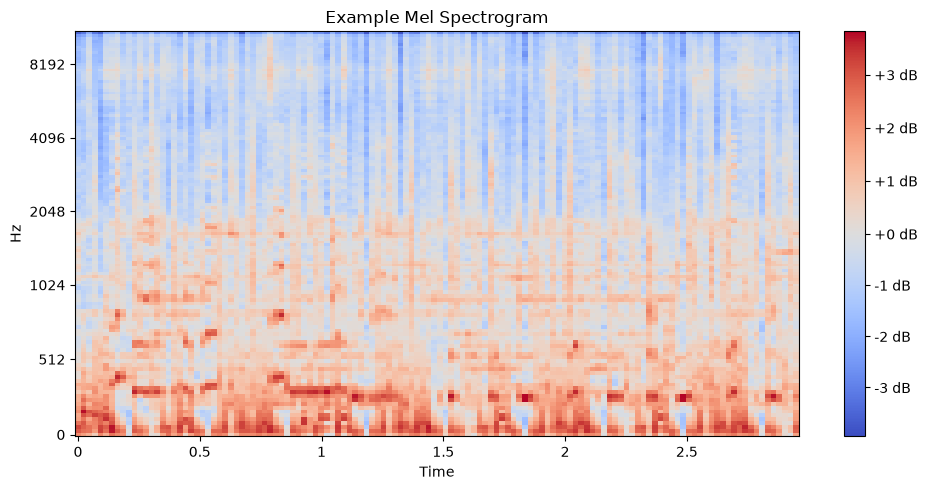

In [44]:
plt.figure(figsize=(10, 5))

librosa.display.specshow(
    mel_spectrograms[0],
    sr=22050,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")

plt.title("Example Mel Spectrogram")

plt.tight_layout()
plt.show()

In [45]:
# Convert genre names into numerical labels
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(
    df["primary_genre"]
)

# Display the mapping
for index, genre in enumerate(label_encoder.classes_):
    print(index, "=", genre)

print("Number of classes:", len(label_encoder.classes_))

0 = alternative rock
1 = electronic
2 = folk
3 = indie rock
4 = pop
5 = rap
6 = rock
7 = soul
Number of classes: 8


In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X_audio,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1280
Testing samples: 320


In [47]:
number_of_genres = len(label_encoder.classes_)

cnn = models.Sequential([

    # Input spectrogram
    layers.Input(shape=(128, 128, 1)),

    # First convolutional block
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # Summarize learned features
    layers.GlobalAveragePooling2D(),

    # Compact song representation
    layers.Dense(
        64,
        activation="relu",
        name="song_embedding"
    ),

    # Genre prediction
    layers.Dense(
        number_of_genres,
        activation="softmax"
    )
])

cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 128, 128, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ song_embedding (Dense)               │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             520 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,448 (396.28 KB)

 Trainable params: 101,448 (396.28 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:
cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [49]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = cnn.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 159ms/step - accuracy: 0.1260 - loss: 2.0804 - val_accuracy: 0.1641 - val_loss: 2.0516
Epoch 2/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 156ms/step - accuracy: 0.1934 - loss: 2.0289 - val_accuracy: 0.2344 - val_loss: 1.9343
Epoch 3/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 148ms/step - accuracy: 0.1934 - loss: 1.9547 - val_accuracy: 0.2578 - val_loss: 1.9088
Epoch 4/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 205ms/step - accuracy: 0.2012 - loss: 1.9274 - val_accuracy: 0.2383 - val_loss: 1.9049
Epoch 5/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 193ms/step - accuracy: 0.2197 - loss: 1.9109 - val_accuracy: 0.2305 - val_loss: 1.9064
Epoch 6/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 203ms/step - accuracy: 0.2324 - loss: 1.8965 - val_accuracy: 0.2422 - val_loss: 1.9007
Epoch 7/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 207ms/step - accuracy: 0.2324 - loss: 1.8868 - val_accuracy: 0.2578 - val_loss: 1.9005
Epoch 8/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 152ms/step - accuracy: 0.2578 - loss: 1.8717 - val_accuracy: 0.

In [50]:
test_loss, test_accuracy = cnn.evaluate(
    X_test,
    y_test
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.3031 - loss: 1.7661
Test loss: 1.7660751342773438
Test accuracy: 0.3031249940395355


In [53]:
predictions = cnn.predict(X_test)

predicted_labels = np.argmax(
    predictions,
    axis=1
)

print(
    classification_report(
        y_test,
        predicted_labels,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step
                  precision    recall  f1-score   support

alternative rock       0.20      0.05      0.08        40
      electronic       0.23      0.07      0.11        40
            folk       0.35      0.50      0.41        40
      indie rock       0.23      0.50      0.31        40
             pop       0.30      0.20      0.24        40
             rap       0.59      0.68      0.63        40
            rock       0.22      0.20      0.21        40
            soul       0.21      0.23      0.22        40

        accuracy                           0.30       320
       macro avg       0.29      0.30      0.28       320
    weighted avg       0.29      0.30      0.28       320



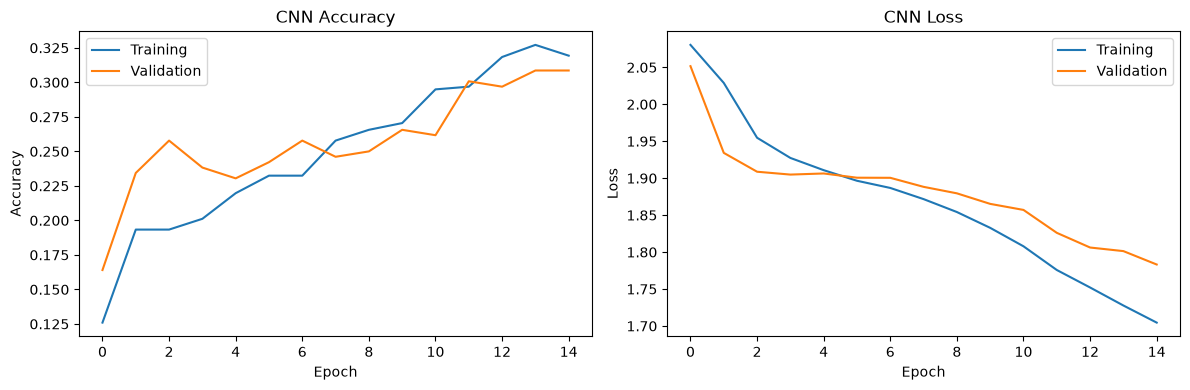

In [54]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [58]:
layers.Input(shape=X_train.shape[1:])
cnn.build((None, 128, 128, 1))

# Create a model that outputs the embedding layer
embedding_model = models.Model(
    inputs=cnn.inputs,
    outputs=cnn.get_layer("song_embedding").output
)

# Generate embeddings for all processed songs
cnn_embeddings = embedding_model.predict(
    X_audio,
    batch_size=32
)

print("CNN embedding shape:", cnn_embeddings.shape)

50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step
CNN embedding shape: (1600, 64)


In [59]:
# Convert genre strings into lists
genre_lists = df["genres"].apply(
    lambda x: [
        genre.strip().lower()
        for genre in x.split(",")
        if genre.strip()
    ]
)

# Convert genre lists into binary features
mlb = MultiLabelBinarizer(sparse_output=False)

genre_features = mlb.fit_transform(genre_lists)

print("Genre feature shape:", genre_features.shape)

Genre feature shape: (1600, 184)


In [60]:
# Scale audio features so they are comparable
scaler = StandardScaler()

scaled_audio_features = scaler.fit_transform(
    X_features
)

print("Audio feature shape:", scaled_audio_features.shape)

Audio feature shape: (1600, 17)


In [61]:
# Compare songs using their genres
genre_similarity = cosine_similarity(
    genre_features
)

# Compare songs using their extracted audio features
audio_similarity = cosine_similarity(
    scaled_audio_features
)

# Compare songs using CNN embeddings
cnn_similarity = cosine_similarity(
    cnn_embeddings
)

print("Genre similarity:", genre_similarity.shape)
print("Audio similarity:", audio_similarity.shape)
print("CNN similarity:", cnn_similarity.shape)

Genre similarity: (1600, 1600)
Audio similarity: (1600, 1600)
CNN similarity: (1600, 1600)


In [62]:
# Combine the similarity scores
combined_similarity = (
    0.20 * genre_similarity +
    0.20 * audio_similarity +
    0.60 * cnn_similarity
)

print("Combined similarity shape:", combined_similarity.shape)

Combined similarity shape: (1600, 1600)


In [64]:
def recommend_by_id(song_id, top_n=5):

    # Find the song in our dataset
    matches = df.index[df["id"] == song_id].tolist()

    if len(matches) == 0:
        print("Song ID not found.")
        return

    # Get the index of the selected song
    song_index = matches[0]

    # Get similarity scores for this song
    similarity_scores = combined_similarity[song_index].copy()

    # Prevent recommending the same song
    similarity_scores[song_index] = -1

    # Find the most similar songs
    similar_indices = np.argsort(
        similarity_scores
    )[::-1][:top_n]

    # Build recommendation results
    recommendations = df.iloc[similar_indices][
        ["id", "artist", "song", "genres"]
    ].copy()

    # Add similarity scores
    recommendations["similarity"] = (
        similarity_scores[similar_indices]
    )

    return recommendations.reset_index(drop=True)

In [65]:
# Display an example song
selected_song = df.iloc[0]

print("Selected song:")
print("Artist:", selected_song["artist"])
print("Song:", selected_song["song"])
print("Genres:", selected_song["genres"])

Selected song:
Artist: Janet Jackson
Song: Empty
Genres: pop,soul


In [66]:
recommendations = recommend_by_id(
    selected_song["id"],
    top_n=5
)

display(recommendations)

,id,artist,song,genres,similarity
0,1kWSR5WNRoDuXFLo,Toni Braxton,Hero,"soul,pop",0.935930
1,GdVffw0VfyVlO35C,Jazmine Sullivan,Switch!,"soul,pop",0.931619
2,9iOJzEpYsrQ5NmnZ,George Michael,Monkey,"pop,pop,soul",0.914470
3,XZww54cye4QOjh9A,Whitney Houston,Love That Man,"pop,soul",0.876850
4,woZCzBlsXPEDBiHZ,Keri Hilson,Knock You Down,pop,0.872944


In [69]:
def recommend_by_title(song_title, top_n=5):

    # Search without worrying about capitalization
    matches = df[
        df["song"].str.contains(
            song_title,
            case=False,
            na=False
        )
    ]

    if len(matches) == 0:
        print("No matching songs found.")
        return

    # Display matching songs if multiple exist
    display(
        matches[["id", "artist", "song", "genres"]].head(10)
    )

    # Use the first matching song
    selected_id = matches.iloc[0]["id"]

    return recommend_by_id(
        selected_id,
        top_n
    )

In [74]:
recommend_by_title("After Thoughts", top_n=5)

No matching songs found.


In [75]:
cnn.save("music_cnn_model.keras")

print("CNN model saved successfully.")

CNN model saved successfully.


In [76]:
np.save(
    "cnn_embeddings.npy",
    cnn_embeddings
)

np.save(
    "combined_similarity.npy",
    combined_similarity
)

df.to_csv(
    "processed_music_data.csv",
    index=False
)